In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"D:\DOWNLOAD\diabetes.csv")
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


In [5]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [6]:
print(df.describe())

       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  120.894531      69.105469      20.536458   79.799479   
std       3.369578   31.972618      19.355807      15.952218  115.244002   
min       0.000000    0.000000       0.000000       0.000000    0.000000   
25%       1.000000   99.000000      62.000000       0.000000    0.000000   
50%       3.000000  117.000000      72.000000      23.000000   30.500000   
75%       6.000000  140.250000      80.000000      32.000000  127.250000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  DiabetesPedigreeFunction         Age     Outcome  
count  768.000000                768.000000  768.000000  768.000000  
mean    31.992578                  0.471876   33.240885    0.348958  
std      7.884160                  0.331329   11.760232    0.476951  
min      0.000000                  

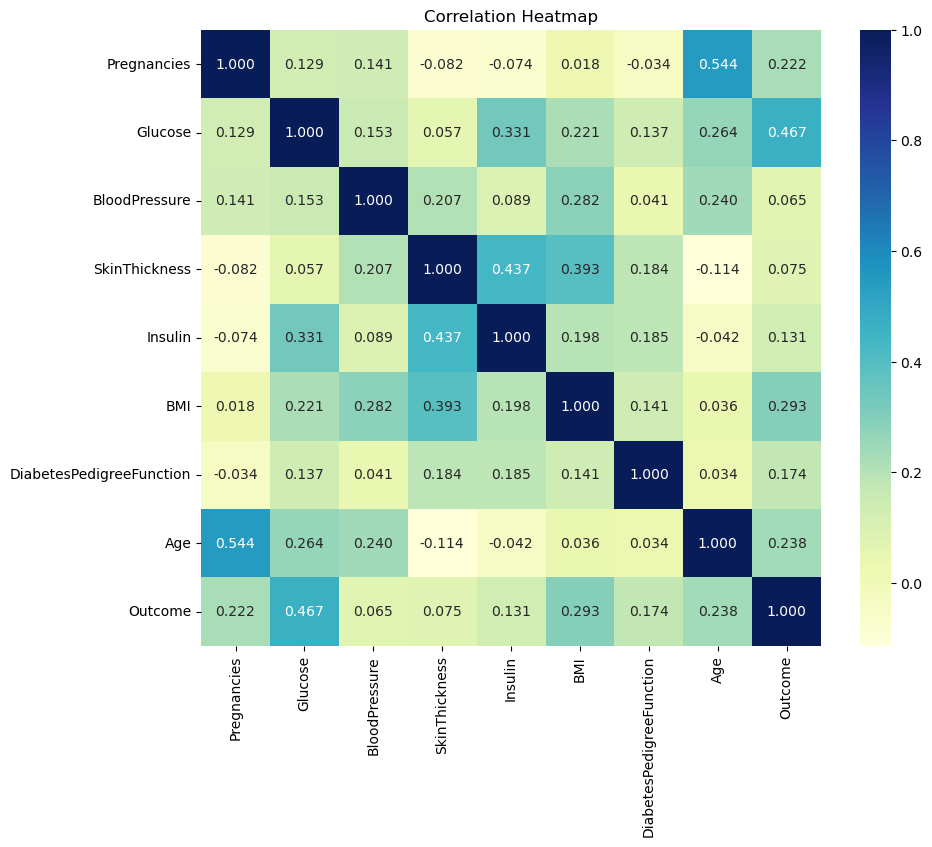

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Correlation Heatmap")
plt.show()

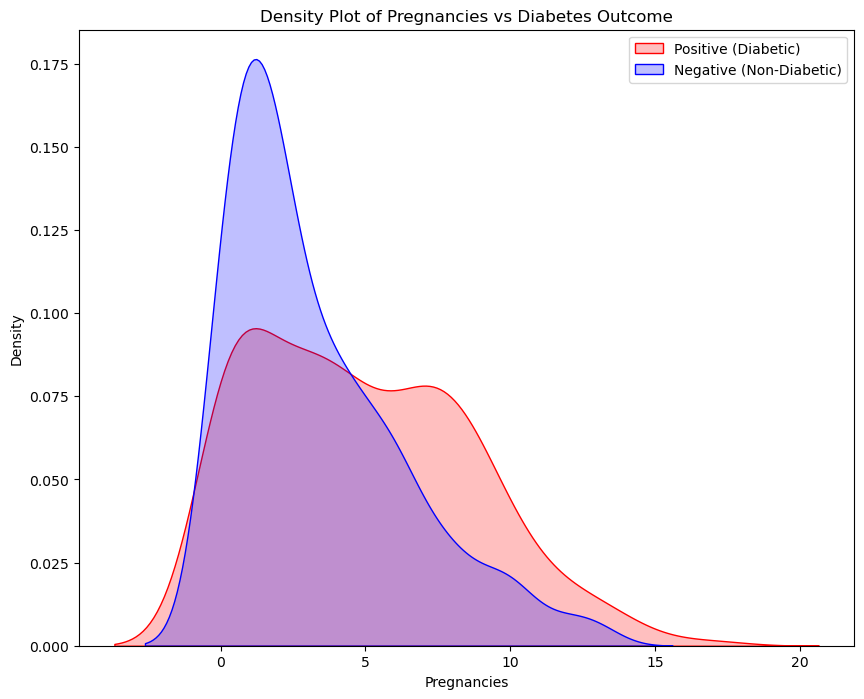

In [13]:
# Exploring pregnancies and target variables
plt.figure(figsize=(10, 8))
sns.kdeplot(df["Pregnancies"][df["Outcome"] == 1],color="red",fill=True)
sns.kdeplot(df["Pregnancies"][df["Outcome"] == 0], color="blue",fill=True)
plt.xlabel("Pregnancies")
plt.ylabel("Density")
plt.legend(["Positive (Diabetic)", "Negative (Non-Diabetic)"])
plt.title("Density Plot of Pregnancies vs Diabetes Outcome")
plt.show()


<Axes: xlabel='Outcome', ylabel='Glucose'>

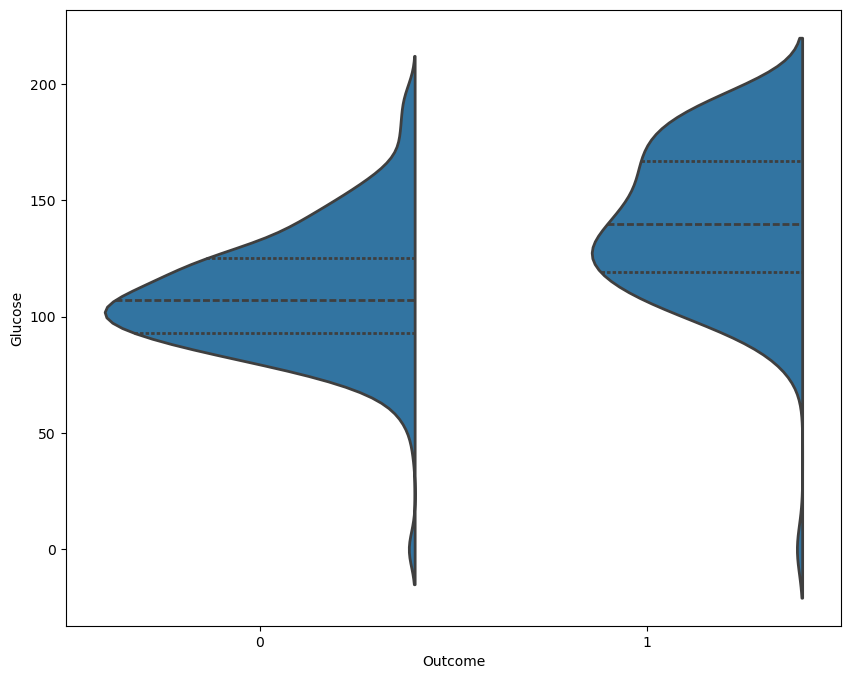

In [9]:
# Exploring Glucose and target variables
plt.figure(figsize =(10,8))
sns.violinplot(data=df,x="Outcome", y="Glucose", split= True, linewidth=2, inner = "quart")

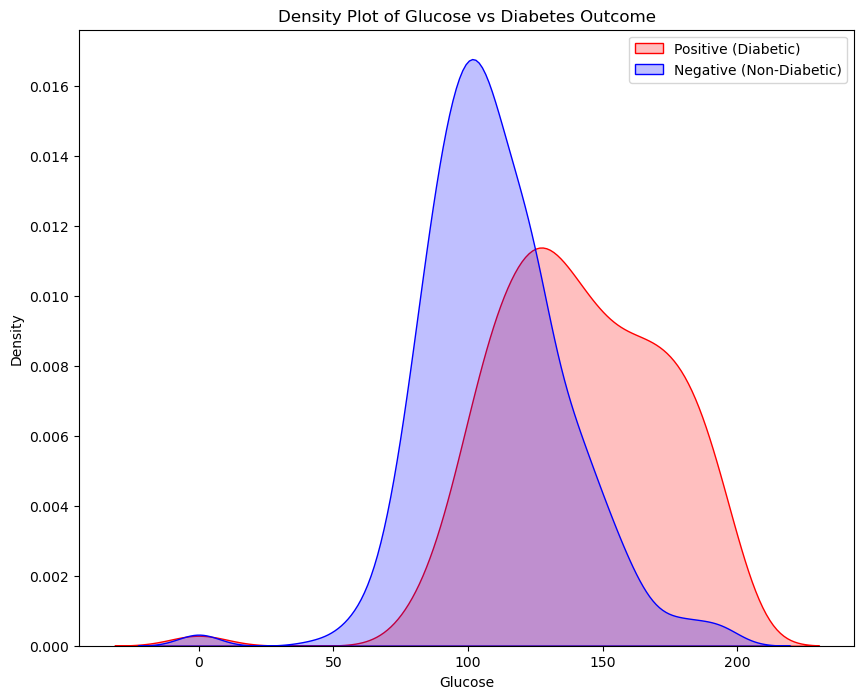

In [10]:
# Exploring Glucose and target variables
plt.figure(figsize=(10, 8))
sns.kdeplot(df["Glucose"][df["Outcome"] == 1],color="red",fill=True)
sns.kdeplot(df["Glucose"][df["Outcome"] == 0], color="blue",fill=True)
plt.xlabel("Glucose")
plt.ylabel("Density")
plt.legend(["Positive (Diabetic)", "Negative (Non-Diabetic)"])
plt.title("Density Plot of Glucose vs Diabetes Outcome")
plt.show()

In [11]:
# Replace 0 values with the mean/median of the respective feature
# Glucose
df["Glucose"] = df["Glucose"].replace(0, df["Glucose"].median())
# BloodPressure
df["BloodPressure"] = df["BloodPressure"].replace(0, df["BloodPressure"].median())
# BMI
df["BMI"] = df["BMI"].replace(0, df["BMI"].mean())
# BMI
df["SkinThickness"] = df["SkinThickness"].replace(0, df["SkinThickness"].mean())
# BMI
df["Insulin"] = df["Insulin"].replace(0, df["Insulin"].mean())

In [12]:
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35.000000,79.799479,33.6,0.627,50,1
1,1,85,66,29.000000,79.799479,26.6,0.351,31,0
2,8,183,64,20.536458,79.799479,23.3,0.672,32,1
3,1,89,66,23.000000,94.000000,28.1,0.167,21,0
4,0,137,40,35.000000,168.000000,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48.000000,180.000000,32.9,0.171,63,0
764,2,122,70,27.000000,79.799479,36.8,0.340,27,0
765,5,121,72,23.000000,112.000000,26.2,0.245,30,0
766,1,126,60,20.536458,79.799479,30.1,0.349,47,1


In [13]:
# Splitting the dependent and independent variable
X = df.drop(["Outcome"], axis = 1)
y = df["Outcome"]

In [14]:
X

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35.000000,79.799479,33.6,0.627,50
1,1,85,66,29.000000,79.799479,26.6,0.351,31
2,8,183,64,20.536458,79.799479,23.3,0.672,32
3,1,89,66,23.000000,94.000000,28.1,0.167,21
4,0,137,40,35.000000,168.000000,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48.000000,180.000000,32.9,0.171,63
764,2,122,70,27.000000,79.799479,36.8,0.340,27
765,5,121,72,23.000000,112.000000,26.2,0.245,30
766,1,126,60,20.536458,79.799479,30.1,0.349,47


In [15]:
y

0      1
1      0
2      1
3      0
4      1
      ..
763    0
764    0
765    0
766    1
767    0
Name: Outcome, Length: 768, dtype: int64

In [16]:
# Splitting the dataset into training and testing dataset
from sklearn.model_selection import train_test_split

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)

In [20]:
X_train

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
464,10,115,98,20.536458,79.799479,24.0,1.022,34
223,7,142,60,33.000000,190.000000,28.8,0.687,61
393,4,116,72,12.000000,87.000000,22.1,0.463,37
766,1,126,60,20.536458,79.799479,30.1,0.349,47
570,3,78,70,20.536458,79.799479,32.5,0.270,39
...,...,...,...,...,...,...,...,...
71,5,139,64,35.000000,140.000000,28.6,0.411,26
106,1,96,122,20.536458,79.799479,22.4,0.207,27
270,10,101,86,37.000000,79.799479,45.6,1.136,38
435,0,141,72,20.536458,79.799479,42.4,0.205,29


In [21]:
# KNN
from sklearn.neighbors import KNeighborsClassifier

In [22]:
training_accuracy = []
test_accuracy = []
for n_neighbors in range(1,11):
    knn = KNeighborsClassifier(n_neighbors=n_neighbors)
    knn.fit(X_train, y_train)

# check accuracy score
    training_accuracy.append(knn.score(X_train, y_train))
    test_accuracy.append(knn.score(X_test, y_test))

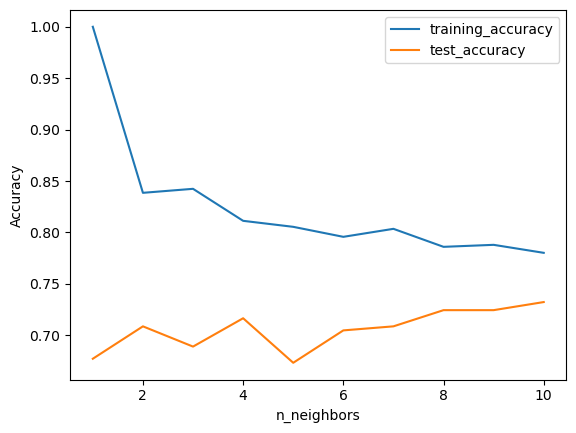

In [23]:
plt.plot(range(1,11), training_accuracy, label = "training_accuracy")
plt.plot(range(1,11), test_accuracy, label = "test_accuracy")
plt.ylabel("Accuracy")
plt.xlabel("n_neighbors")
plt.legend()

In [24]:
knn = KNeighborsClassifier(n_neighbors=9)
knn. fit(X_train, y_train)
print(knn.score(X_train, y_train), ": Training accuracy")
print(knn.score(X_test, y_test), ": Test accuracy")

0.7879377431906615 : Training accuracy
0.7244094488188977 : Test accuracy


In [25]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(random_state=0)
dt.fit(X_train, y_train)
print(dt.score(X_train, y_train), ": Training accuracy")
print(dt.score(X_test, y_test), ": Test accuracy")

1.0 : Training accuracy
0.6811023622047244 : Test accuracy


In [26]:
dt1 = DecisionTreeClassifier(random_state=0, max_depth=3)
dt1.fit(X_train, y_train)
print(dt1.score(X_train, y_train), ": Training accuracy")
print(dt1.score(X_test, y_test), ": Test accuracy")

0.77431906614786 : Training accuracy
0.6929133858267716 : Test accuracy


In [27]:
from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(random_state=42)
mlp.fit(X_train, y_train)
print(mlp.score(X_train, y_train), ": Training accuracy")
print(mlp.score(X_test, y_test), ": Test accuracy")

0.7509727626459144 : Training accuracy
0.6811023622047244 : Test accuracy


In [28]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train_scaled = sc.fit_transform(X_train)
X_test_scaled = sc.fit_transform(X_test)

In [29]:
mlp1 = MLPClassifier(random_state=0)
mlp1.fit(X_train_scaled, y_train)
print(mlp1.score(X_train_scaled, y_train), ": Training accuracy")
print(mlp1.score(X_test_scaled, y_test), ": Test accuracy")

0.8326848249027238 : Training accuracy
0.7322834645669292 : Test accuracy


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
